# Model Interpretation and Explainability

## Objective

The objective of this notebook is to interpret the trained Logistic Regression model and understand how different cardiovascular health-related variables influence its predictions.

## 1. Reconstructing the Final Model

The final Logistic Regression model selected during cross-validation and hyperparameter tuning is reconstructed using the same preprocessing configuration.

The model uses median imputation and standardisation for numerical variables, most-frequent imputation and one-hot encoding for categorical variables, and Logistic Regression with C = 1.

The same train-test split is retained to ensure consistency with the previous evaluation.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Load dataset
df = pd.read_csv("../data/raw/heart_disease_data.csv")

# Separate features and target
X = df.drop(columns=["num"]).copy()
y = (df["num"] > 0).astype(int)

# Reproducing the original train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Define feature groups
num_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

cat_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

# Numerical preprocessing
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline, cat_features)
])

# Final Logistic Regression pipeline
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=1,
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [2]:
# Extracting the fitted preprocessing and classifier
fitted_preprocessor = final_model.named_steps["preprocessor"]
logistic_model = final_model.named_steps["classifier"]

# feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = logistic_model.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df = coefficient_df.sort_values(
    by="Coefficient",
    ascending=False
)

display(coefficient_df)

,Feature,Coefficient
10,cat__cp_4.0,1.030561
27,cat__thal_7.0,0.818491
6,cat__sex_1.0,0.690353
23,cat__ca_2.0,0.642171
19,cat__slope_2.0,0.603427
24,cat__ca_3.0,0.494233
22,cat__ca_1.0,0.351754
1,num__trestbps,0.340559
17,cat__exang_1.0,0.259632
4,num__oldpeak,0.259525


In [3]:
numerical_coefficients = coefficient_df[
    coefficient_df["Feature"].str.startswith("num__")
].copy()

# odds ratios
numerical_coefficients["Odds_Ratio"] = np.exp(
    numerical_coefficients["Coefficient"]
)

# results
numerical_odds_ratios = numerical_coefficients[
    ["Feature", "Coefficient", "Odds_Ratio"]
].sort_values(
    by="Odds_Ratio",
    ascending=False
)

display(numerical_odds_ratios)

,Feature,Coefficient,Odds_Ratio
1,num__trestbps,0.340559,1.405733
4,num__oldpeak,0.259525,1.296315
2,num__chol,0.178920,1.195925
0,num__age,-0.060936,0.940883
3,num__thalach,-0.372474,0.689028


### Numerical Feature Odds Ratio Analysis

Odds ratios were calculated by exponentiating the Logistic Regression coefficients.

Since numerical variables were standardised each odds ratio represents the change in predicted odds associated with a one standard-deviation increase in the corresponding feature, holding other model inputs constant.

Key observations:

- Resting blood pressure had the largest positive numerical coefficient (OR = 1.406).
- Oldpeak (OR = 1.296) and cholesterol (OR = 1.196) also showed positive model associations.
- Maximum heart rate showed a negative model association (OR = 0.689).
- Age had an odds ratio close to 1 (OR = 0.941).

These findings describe the fitted model's conditional associations. They should not be interpreted as causal effects or independent clinical risk estimates.

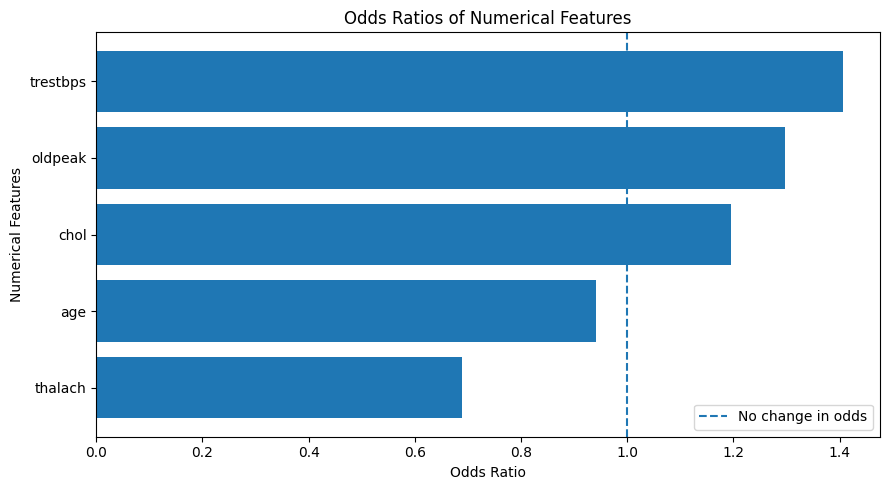

In [4]:
# visualising numerical odds ratio
import matplotlib.pyplot as plt

plot_data = numerical_odds_ratios.sort_values("Odds_Ratio")

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data["Feature"].str.replace("num__", "", regex=False),
    plot_data["Odds_Ratio"]
)

plt.axvline(
    x=1,
    linestyle="--",
    label="No change in odds"
)

plt.xlabel("Odds Ratio")
plt.ylabel("Numerical Features")
plt.title("Odds Ratios of Numerical Features")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation of Numerical Feature Odds Ratios

The visualisation indicates that resting blood pressure, oldpeak and cholesterol have odds ratios greater than 1, while age and maximum heart rate have odds ratios below 1.

Resting blood pressure showed the largest positive association with the model's predicted odds, whereas maximum heart rate showed the largest negative association among the numerical features.

The dashed reference line at OR = 1 represents no change in odds.

These relationships are conditional on the other model inputs and should not be interpreted as causal effects or clinical risk estimates.

In [5]:
# interpreting categorical coefficients
# Numerical preprocessing remains unchanged

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing with reference category encoding
cat_pipeline_reference = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first"
    ))
])

# Combining preprocessing
interpretation_preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline_reference, cat_features)
])

# Building interpretation model
interpretation_model = Pipeline([
    ("preprocessor", interpretation_preprocessor),
    ("classifier", LogisticRegression(
        C=1,
        max_iter=1000,
        random_state=42
    ))
])

# Fitting
interpretation_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transforme

In [6]:
# Extracting categorical odds ratio

fitted_preprocessor = interpretation_model.named_steps["preprocessor"]
logistic_model = interpretation_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = logistic_model.coef_[0]

interpretation_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Keeping categorical features only
categorical_coefficients = interpretation_df[
    interpretation_df["Feature"].str.startswith("cat__")
].copy()

categorical_coefficients["Odds_Ratio"] = np.exp(
    categorical_coefficients["Coefficient"]
)

categorical_odds_ratios = categorical_coefficients.sort_values(
    by="Odds_Ratio",
    ascending=False
)

display(categorical_odds_ratios)

,Feature,Coefficient,Odds_Ratio
15,cat__ca_1.0,1.467563,4.338649
16,cat__ca_2.0,1.452622,4.274308
8,cat__cp_4.0,1.345419,3.839797
19,cat__thal_7.0,1.261638,3.531200
5,cat__sex_1.0,1.221453,3.392113
17,cat__ca_3.0,1.113827,3.045994
13,cat__slope_2.0,0.801673,2.229267
12,cat__exang_1.0,0.461791,1.586914
11,cat__restecg_2.0,0.377178,1.458165
6,cat__cp_2.0,0.355494,1.426885


### Categorical Feature Odds Ratio Analysis

Categorical feature odds ratios were calculated using reference-category encoding.

Key observations:

- `ca_1.0` showed the largest positive association (OR = 4.34) relative to `ca_0.0`.
- `ca_2.0` also showed a strong positive association (OR = 4.27).
- `cp_4.0` had an odds ratio of 3.84 relative to `cp_1.0`.
- `thal_7.0` had an odds ratio of 3.53 relative to `thal_3.0`.
- `sex_1.0` had an odds ratio of 3.39 relative to `sex_0.0`.

Some categorical levels had odds ratios below 1, indicating lower modelled odds relative to their respective reference categories.

These findings describe conditional associations learned by the fitted model. They do not establish causality, statistical significance, or clinical risk.

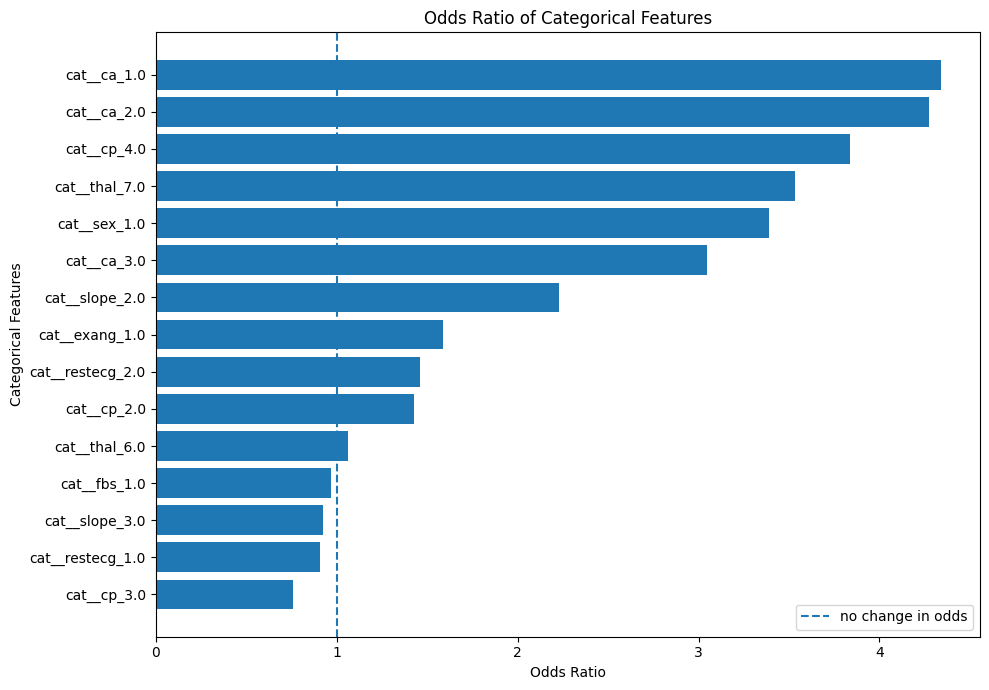

In [7]:
# visualizing categorical ods ratio

plot_data= categorical_odds_ratios.sort_values("Odds_Ratio")

plt.figure(figsize=(10,7))

plt.barh(plot_data["Feature"].replace("cat__", "", regex=False),
         plot_data["Odds_Ratio"])

plt.axvline(x=1,linestyle="--",label="no change in odds")

plt.xlabel("Odds Ratio")
plt.ylabel("Categorical Features")
plt.title("Odds Ratio of Categorical Features")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation of Categorical Feature Odds Ratios

The categorical odds ratio visualisation highlights differences in modelled odds across category levels.

The strongest positive associations were observed for `ca_1.0` (OR = 4.34), `ca_2.0` (OR = 4.27), and `cp_4.0` (OR = 3.84), relative to their respective reference categories.

The `cp_3.0` category showed the lowest odds ratio (OR = 0.76).

These findings illustrate how categorical feature levels contribute to the Logistic Regression model's predictions. The results are conditional model associations and should not be interpreted as causal effects or clinical conclusions.

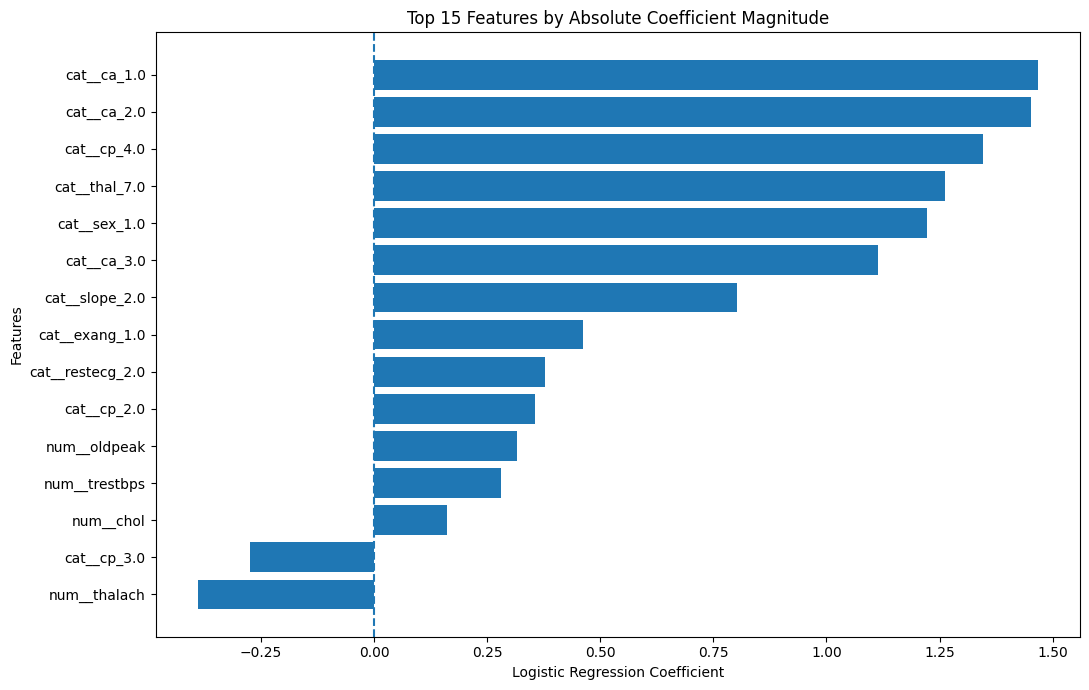

In [8]:
# combining all features coefficients
all_feature_coefficients = interpretation_df.copy()

# sorting by absolute coef magnitude
all_feature_coefficients["Absolute_Coefficient"] = (all_feature_coefficients["Coefficient"].abs())

top_features = all_feature_coefficients.sort_values(
    by="Absolute_Coefficient",
    ascending=False
).head(15)

# visualisation
top_features = top_features.sort_values("Coefficient")

# Plot
plt.figure(figsize=(11, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")
plt.title("Top 15 Features by Absolute Coefficient Magnitude")

plt.tight_layout()
plt.show()

### Overall Feature Coefficient Analysis

The combined coefficient visualisation highlights the strongest positive and negative coefficients in the reference-category Logistic Regression model.

Key observations:

- `ca_1.0` and `ca_2.0` showed the largest positive coefficients.
- `cp_4.0`, `thal_7.0`, and `sex_1.0` also showed relatively strong positive coefficients.
- `thalach` showed the largest negative coefficient among the displayed features.
- `cp_3.0` also showed a negative coefficient.

The results indicate that categorical variables, particularly the number of major vessels (`ca`) and chest pain type (`cp`), contribute substantially to the fitted model's linear predictions.

Coefficient magnitudes must be interpreted in the context of feature scaling and encoding. These results describe model behaviour rather than causal relationships or clinical importance.

In [9]:
from sklearn.base import clone

# Setting number of bootstrap repetitions
n_bootstraps = 300

# Fixing categorical levels using training data
category_levels = [
    np.sort(X_train[col].dropna().unique())
    for col in cat_features
]

# Creating a consistent preprocessing pipeline
bootstrap_cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        categories=category_levels,
        handle_unknown="ignore",
        drop="first"
    ))
])

bootstrap_preprocessor = ColumnTransformer([
    ("num", clone(num_pipeline), num_features),
    ("cat", bootstrap_cat_pipeline, cat_features)
])

bootstrap_model = Pipeline([
    ("preprocessor", bootstrap_preprocessor),
    ("classifier", LogisticRegression(
        C=1,
        max_iter=1000,
        random_state=42
    ))
])

# Storing bootstrap coefficients
rng = np.random.default_rng(42)

bootstrap_coefficients = []

n_samples = len(X_train)

for i in range(n_bootstraps):

    # Sample training observations with replacement
    sampled_indices = rng.integers(0, n_samples, size=n_samples)

    X_boot = X_train.iloc[sampled_indices]
    y_boot = y_train.iloc[sampled_indices]

    # Fitting model on bootstrap sample
    bootstrap_model.fit(X_boot, y_boot)

    # Store coefficients
    bootstrap_coefficients.append(
        bootstrap_model.named_steps["classifier"].coef_[0]
    )

# results into dataframe
bootstrap_feature_names = (
    bootstrap_model.named_steps["preprocessor"].get_feature_names_out()
)

bootstrap_coefficient_df = pd.DataFrame(
    bootstrap_coefficients,
    columns=bootstrap_feature_names
)

print("Bootstrap repetitions completed:", len(bootstrap_coefficient_df))
print("Number of features:", len(bootstrap_feature_names))
print("Bootstrap analysis completed successfully.")

Bootstrap repetitions completed: 300
Number of features: 20
Bootstrap analysis completed successfully.


In [10]:
# calculating bootstrap coefficients
bootstrap_summary = pd.DataFrame({
    "Mean_Coefficient": bootstrap_coefficient_df.mean(),
    "Std_Coefficient": bootstrap_coefficient_df.std(),
    "Lower_95%": bootstrap_coefficient_df.quantile(0.025),
    "Upper_95%": bootstrap_coefficient_df.quantile(0.975),
    "Positive_%": (bootstrap_coefficient_df > 0).mean() * 100
})

bootstrap_summary["Absolute_Mean"] = (
    bootstrap_summary["Mean_Coefficient"].abs()
)

bootstrap_summary = bootstrap_summary.sort_values(
    "Absolute_Mean",
    ascending=False
)

display(bootstrap_summary.round(4))

,Mean_Coefficient,Std_Coefficient,Lower_95%,Upper_95%,Positive_%,Absolute_Mean
cat__ca_1.0,1.5424,0.3934,0.8137,2.3033,100.0000,1.5424
cat__ca_2.0,1.4281,0.4390,0.6031,2.2099,100.0000,1.4281
cat__cp_4.0,1.4012,0.3906,0.6232,2.1413,100.0000,1.4012
cat__thal_7.0,1.3636,0.3322,0.7041,1.9861,100.0000,1.3636
cat__sex_1.0,1.2822,0.3506,0.6551,1.9495,100.0000,1.2822
cat__ca_3.0,1.0755,0.4977,0.0900,1.9643,98.0000,1.0755
cat__slope_2.0,0.7934,0.3603,0.1062,1.5460,98.3333,0.7934
cat__exang_1.0,0.4820,0.3335,-0.1755,1.1117,91.6667,0.4820
num__thalach,-0.4233,0.2576,-0.8995,0.0627,4.0000,0.4233
cat__restecg_2.0,0.3980,0.3768,-0.3613,1.1060,86.6667,0.3980


### Bootstrap Analysis of Coefficient Stability

A bootstrap analysis with 300 resamples was conducted using the training dataset to investigate the stability of Logistic Regression coefficients.

Key findings:

- `ca_1.0`, `ca_2.0`, `cp_4.0`, `thal_7.0`, and `sex_1.0` maintained positive coefficient directions across all 300 bootstrap samples.
- `ca_3.0` and `slope_2.0` also showed highly consistent positive directions.
- `restecg_1.0` maintained a negative coefficient direction across all bootstrap samples.
- Several features, including `thalach`, `oldpeak`, `trestbps`, and `chol`, had 95% bootstrap percentile intervals crossing zero.

These findings suggest that coefficient stability varies across features. Some categorical predictors showed relatively consistent coefficient directions, whereas several numerical predictors exhibited greater uncertainty.

The analysis is limited by the small dataset size and the use of 300 bootstrap repetitions. Bootstrap stability does not establish causality or clinical significance.

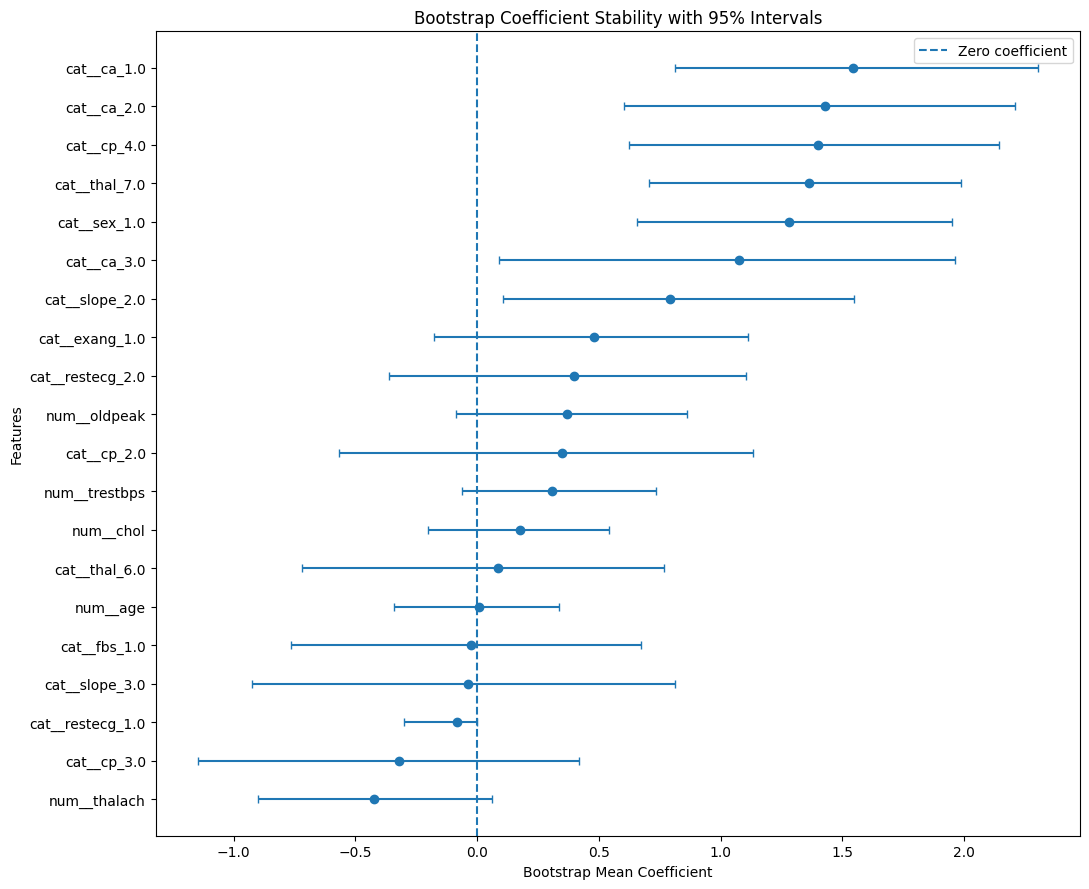

In [11]:
# bootstrap results for plotting
plot_df = bootstrap_summary.sort_values(
    "Mean_Coefficient"
).copy()

# Calculating asymmetric error bars
lower_error = (
    plot_df["Mean_Coefficient"] - plot_df["Lower_95%"]
)

upper_error = (
    plot_df["Upper_95%"] - plot_df["Mean_Coefficient"]
)

plt.figure(figsize=(11, 9))

plt.errorbar(
    plot_df["Mean_Coefficient"],
    plot_df.index,
    xerr=[lower_error, upper_error],
    fmt="o",
    capsize=3
)

plt.axvline(
    x=0,
    linestyle="--",
    label="Zero coefficient"
)

plt.xlabel("Bootstrap Mean Coefficient")
plt.ylabel("Features")
plt.title("Bootstrap Coefficient Stability with 95% Intervals")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation of Bootstrap Coefficient Stability

The bootstrap coefficient stability plot illustrates the variability of Logistic Regression coefficients across 300 resampled training datasets.

Seven features (`ca_1.0`, `ca_2.0`, `cp_4.0`, `thal_7.0`, `sex_1.0`, `ca_3.0`, and `slope_2.0`) had 95% bootstrap percentile intervals entirely above zero.

Several other features had intervals crossing or touching zero, indicating greater uncertainty in their estimated coefficient directions.

The results suggest that coefficient stability varies across predictors. In particular, some categorical feature levels demonstrated more consistent positive associations than several numerical predictors.

These intervals describe bootstrap variability and should not be interpreted as definitive evidence of statistical significance or causal effects.

In [12]:
stability_summary = bootstrap_summary.copy()

def classify_stability(row):
    if row["Lower_95%"] > 0:
        return "Consistently Positive"
    elif row["Upper_95%"] < 0:
        return "Consistently Negative"
    else:
        return "Includes or Touches Zero"

stability_summary["Direction_Stability"] = (
    stability_summary.apply(classify_stability, axis=1)
)

display(
    stability_summary[
        [
            "Mean_Coefficient",
            "Lower_95%",
            "Upper_95%",
            "Positive_%",
            "Direction_Stability"
        ]
    ]
)

,Mean_Coefficient,Lower_95%,Upper_95%,Positive_%,Direction_Stability
cat__ca_1.0,1.542433,0.813720,2.303290,100.000000,Consistently Positive
cat__ca_2.0,1.428132,0.603150,2.209911,100.000000,Consistently Positive
cat__cp_4.0,1.401235,0.623237,2.141338,100.000000,Consistently Positive
cat__thal_7.0,1.363600,0.704103,1.986110,100.000000,Consistently Positive
cat__sex_1.0,1.282231,0.655083,1.949503,100.000000,Consistently Positive
cat__ca_3.0,1.075546,0.089956,1.964335,98.000000,Consistently Positive
cat__slope_2.0,0.793359,0.106150,1.546033,98.333333,Consistently Positive
cat__exang_1.0,0.482047,-0.175490,1.111723,91.666667,Includes or Touches Zero
num__thalach,-0.423270,-0.899473,0.062659,4.000000,Includes or Touches Zero
cat__restecg_2.0,0.397985,-0.361348,1.105988,86.666667,Includes or Touches Zero


### Bootstrap Coefficient Stability Classification

The coefficient stability analysis classified the 20 transformed features into three groups based on their 95% bootstrap percentile intervals.

**Summary:**

- 7 features had intervals entirely above zero, indicating consistently positive coefficient directions.
- 13 features had intervals crossing or touching zero.
- No feature had an interval entirely below zero.

The most consistently positive coefficients belonged to `ca_1.0`, `ca_2.0`, `cp_4.0`, `thal_7.0`, `sex_1.0`, `ca_3.0`, and `slope_2.0`.

Although `restecg_1.0` had a negative coefficient in all 300 bootstrap samples, its upper interval touched zero.

Overall, the analysis demonstrates variation in coefficient stability across predictors. The findings should be interpreted cautiously because of the small dataset, regularisation and finite number of bootstrap repetitions.

Bootstrap intervals describe sampling variability and do not independently establish statistical significance, causality, or clinical importance.